# DSCI 552 — Homework 7
**Name:** Chengfeng Tang  
**GitHub username:** tcf2021  
**USC ID:** 5488902262

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support,
                             roc_curve, roc_auc_score)
from sklearn.preprocessing import label_binarize
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
from threadpoolctl import threadpool_limits
ROOT=Path("..") if Path("../data/anuran").is_dir() else Path(".")
sys.path.insert(0,str((ROOT/"src").resolve()))
from hw7_utils import (SEED,LABELS,scores,tune_models,monte_carlo,MulticlassChain)
OUT=ROOT/"results";OUT.mkdir(exist_ok=True)
thread_limits=threadpool_limits(limits=1)
def figure(name):
    plt.savefig(OUT/(name+".png"),dpi=140,bbox_inches="tight")
    plt.show()
def answer(text):
    display(Markdown(text))
def table(df,name):
    df.to_csv(OUT/(name+".csv"),index=False)
    display(df.round(6))

## 1(a). Data and random split
I used all 22 MFCC attributes and the three categorical responses. RecordID is an identifier, not a predictor. I randomly assigned 70% of the rows to training with seed 552, keeping the remaining rows for testing. This is a row-level split as specified; syllables from the same recording can appear in both sets, so these results do not estimate performance on entirely new recordings.

In [2]:
df=pd.read_csv(ROOT/"data/anuran/Frogs_MFCCs.csv")
features=[x for x in df.columns if x.startswith("MFCCs_")]
X=df[features].to_numpy();Y=df[LABELS].to_numpy()
assert X.shape==(7195,22) and np.isfinite(X).all()
train_idx,test_idx=train_test_split(np.arange(len(df)),train_size=.7,random_state=SEED)
xtr,xte=X[train_idx],X[test_idx];ytr,yte=Y[train_idx],Y[test_idx]
table(pd.DataFrame({"row_index":np.r_[train_idx,test_idx],"split":["train"]*len(train_idx)+["test"]*len(test_idx)}),"split")
print("Training:",len(train_idx),"Test:",len(test_idx))
counts=pd.concat([df[name].value_counts().rename_axis("class").reset_index(name="count").assign(label=name) for name in LABELS])
table(counts,"class_counts")
assert all(pd.Series(ytr[:,j]).value_counts().min()>=10 for j in range(3))

Training: 5036 Test: 2159


,row_index,split
0,2535,train
1,1557,train
2,5683,train
3,4024,train
4,71,train
...,...,...
7190,2696,test
7191,5572,test
7192,7034,test
7193,1703,test


,class,count,label
0,Leptodactylidae,4420,Family
1,Hylidae,2165,Family
2,Dendrobatidae,542,Family
3,Bufonidae,68,Family
0,Adenomera,4150,Genus
1,Hypsiboas,1593,Genus
2,Ameerega,542,Genus
3,Dendropsophus,310,Genus
4,Leptodactylus,270,Genus
5,Scinax,148,Genus


## 1(b)(i). Evaluation measures
Each observation has three categorical labels. Let $r_i$ be the number of correctly predicted labels for row $i$.

- **Exact match**: $n^{-1}\sum_i\mathbf{1}(r_i=3)$.
- **Mean Hamming distance**: $n^{-1}\sum_i(3-r_i)$, ranging from 0 to 3.
- **Hamming loss**: $(3n)^{-1}\sum_i(3-r_i)$.
- **Hamming score (label accuracy)**: $1-\text{Hamming loss}$.
- **Example-based Jaccard score**: $n^{-1}\sum_i r_i/(6-r_i)$.

I report both score conventions because “Hamming score” is sometimes used for the example-based set overlap. For Jaccard, each label is tagged by its output name, so Family and Genus are distinct label spaces. Hamming loss here uses the three categorical outputs, not a flattened 22-column one-hot representation.

## 1(b)(ii). Gaussian SVMs
I fitted one multi-class classifier for each output using an explicit one-versus-rest wrapper around binary SVCs. The kernel is $\exp(-\gamma\|x-z\|^2)$, where $\gamma=1/(2\sigma^2)$. I used the original normalized MFCC values.

For each output, I selected $C\in\{1,10,100\}$ and $\gamma\in\{0.1,1,10\}$ by mean accuracy in ten stratified training folds. A tie uses the first grid combination. The test set is held out during every parameter search. These are best values within the stated grid, not continuous global optima.

In [3]:
summary=[];parameters=[];all_models={}
def evaluate(name,models):
    all_models[name]=models
    for split,x,y in [("Train",xtr,ytr),("Test",xte,yte)]:
        pred=np.column_stack([model.predict(x) for model in models])
        summary.append({"model":name,"split":split,**scores(y,pred)})
        pd.DataFrame(pred,columns=LABELS).assign(row_index=train_idx if split=="Train" else test_idx).to_csv(OUT/(name.replace(" ","_")+"_"+split+"_predictions.csv"),index=False)
    display(pd.DataFrame(summary).tail(2).round(6))
rbf,pr=tune_models(xtr,ytr,"RBF",OUT)
parameters.extend(pr);table(pd.DataFrame(pr),"rbf_selected_parameters")
evaluate("RBF",rbf)

,model,label,C,gamma,sigma,cv_accuracy
0,RBF,Family,100,1,0.707107,0.992255
1,RBF,Genus,10,1,0.707107,0.990271
2,RBF,Species,10,1,0.707107,0.989473


,model,split,exact_match,mean_hamming_distance,hamming_loss,hamming_score,jaccard_score
0,RBF,Train,0.998411,0.002780,0.000927,0.999073,0.998848
1,RBF,Test,0.985642,0.030107,0.010036,0.989964,0.988698


## 1(b)(iii). L1-penalized linear SVMs
I standardized each feature using only the fitting fold. I used LinearSVC with an L1 penalty, squared-hinge loss, and one-versus-rest multi-class classification. For each output, ten-fold stratified CV selected $C$ from $\{0.01,0.1,1,10,100\}$. The final scaler and classifier were then fitted on the complete training partition.

In [4]:
linear,pl=tune_models(xtr,ytr,"L1",OUT)
parameters.extend(pl);table(pd.DataFrame(pl),"l1_selected_parameters")
evaluate("L1",linear)

,model,label,C,gamma,sigma,cv_accuracy
0,L1,Family,1,NaN,NaN,0.937849
1,L1,Genus,10,NaN,NaN,0.954729
2,L1,Species,1,NaN,NaN,0.958101


,model,split,exact_match,mean_hamming_distance,hamming_loss,hamming_score,jaccard_score
2,L1,Train,0.921366,0.141183,0.047061,0.952939,0.944142
3,L1,Test,0.917554,0.157943,0.052648,0.947352,0.939000


## 1(b)(iv). Compensating for imbalance
I repeated the standardized L1 procedure with inverse-frequency class weights. This is the alternative to SMOTE permitted in the assignment. A class with fewer observations receives more weight; the weights are recalculated from the fitting fold, and the validation rows keep their original frequencies. I used the same C grid and ten-fold splits as in 1(b)(iii).

In [5]:
weighted,pw=tune_models(xtr,ytr,"L1 balanced",OUT)
parameters.extend(pw);table(pd.DataFrame(pw),"weighted_selected_parameters")
evaluate("L1 balanced",weighted)
comparison=pd.DataFrame(summary)
table(comparison,"supervised_comparison")
test=comparison.loc[comparison.split=="Test"].set_index("model")
best=test.exact_match.idxmax()
answer(f'{best} has the highest test exact match among the three baselines ({test.loc[best,"exact_match"]:.2%}). '
       f'Class weighting changes L1 test Hamming loss from {test.loc["L1","hamming_loss"]:.4f} to {test.loc["L1 balanced","hamming_loss"]:.4f}. '
       f'Exact match changes from {test.loc["L1","exact_match"]:.2%} to {test.loc["L1 balanced","exact_match"]:.2%}.')

,model,label,C,gamma,sigma,cv_accuracy
0,L1 balanced,Family,10,NaN,NaN,0.931494
1,L1 balanced,Genus,10,NaN,NaN,0.947979
2,L1 balanced,Species,1,NaN,NaN,0.958101


,model,split,exact_match,mean_hamming_distance,hamming_loss,hamming_score,jaccard_score
4,L1 balanced,Train,0.914615,0.146346,0.048782,0.951218,0.940985
5,L1 balanced,Test,0.903659,0.176934,0.058978,0.941022,0.930431


,model,split,exact_match,mean_hamming_distance,hamming_loss,hamming_score,jaccard_score
0,RBF,Train,0.998411,0.002780,0.000927,0.999073,0.998848
1,RBF,Test,0.985642,0.030107,0.010036,0.989964,0.988698
2,L1,Train,0.921366,0.141183,0.047061,0.952939,0.944142
3,L1,Test,0.917554,0.157943,0.052648,0.947352,0.939000
4,L1 balanced,Train,0.914615,0.146346,0.048782,0.951218,0.940985
5,L1 balanced,Test,0.903659,0.176934,0.058978,0.941022,0.930431


RBF has the highest test exact match among the three baselines (98.56%). Class weighting changes L1 test Hamming loss from 0.0526 to 0.0590. Exact match changes from 91.76% to 90.37%.

## 1(b)(v). Extra practice: classifier chain
I used the order Family → Genus → Species. Each later Gaussian SVM receives the MFCCs and one-hot encodings of earlier labels. Training uses observed earlier labels; prediction uses earlier predictions. I reused the Gaussian hyperparameters selected in 1(b)(ii), without additional test-based tuning. The chain can exploit label dependence, but errors can propagate from one stage to the next.

In [6]:
chain=MulticlassChain(pr).fit(xtr,ytr)
chain_rows=[]
for split,x,y in [("Train",xtr,ytr),("Test",xte,yte)]:
    chain_rows.append({"model":"Classifier chain","split":split,**scores(y,chain.predict(x))})
table(pd.DataFrame(chain_rows),"chain_results")
answer(f'Test exact match is {chain_rows[1]["exact_match"]:.2%}, versus {test.loc["RBF","exact_match"]:.2%} for independent Gaussian classifiers.')

,model,split,exact_match,mean_hamming_distance,hamming_loss,hamming_score,jaccard_score
0,Classifier chain,Train,0.999603,0.000596,0.000199,0.999801,0.999742
1,Classifier chain,Test,0.988421,0.031496,0.010499,0.989501,0.989115


Test exact match is 98.84%, versus 98.56% for independent Gaussian classifiers.

The chain improves exact match from 98.56% to 98.84%, but Hamming loss increases slightly from 0.01004 to 0.01050. Thus fewer rows have any wrong label, while the total number of wrong label entries is slightly larger. The two metrics reward different aspects of the predictions.

## 1(b)(vi). Extra practice: per-class evaluation
For each baseline and output, I treat each category as positive against the other categories. Precision is TP/(TP+FP), recall is TP/(TP+FN), and F1 is their harmonic mean. I use zero when a precision denominator is zero. Macro averages give every category equal weight. The ROC curves vary the decision-score cutoff; AUC is computed from those scores without requiring calibrated probabilities.

Each confusion matrix below has actual categories as rows and predicted categories as columns. The CSV files preserve full category names. The plots show test results; the summary includes both training and test macro metrics.

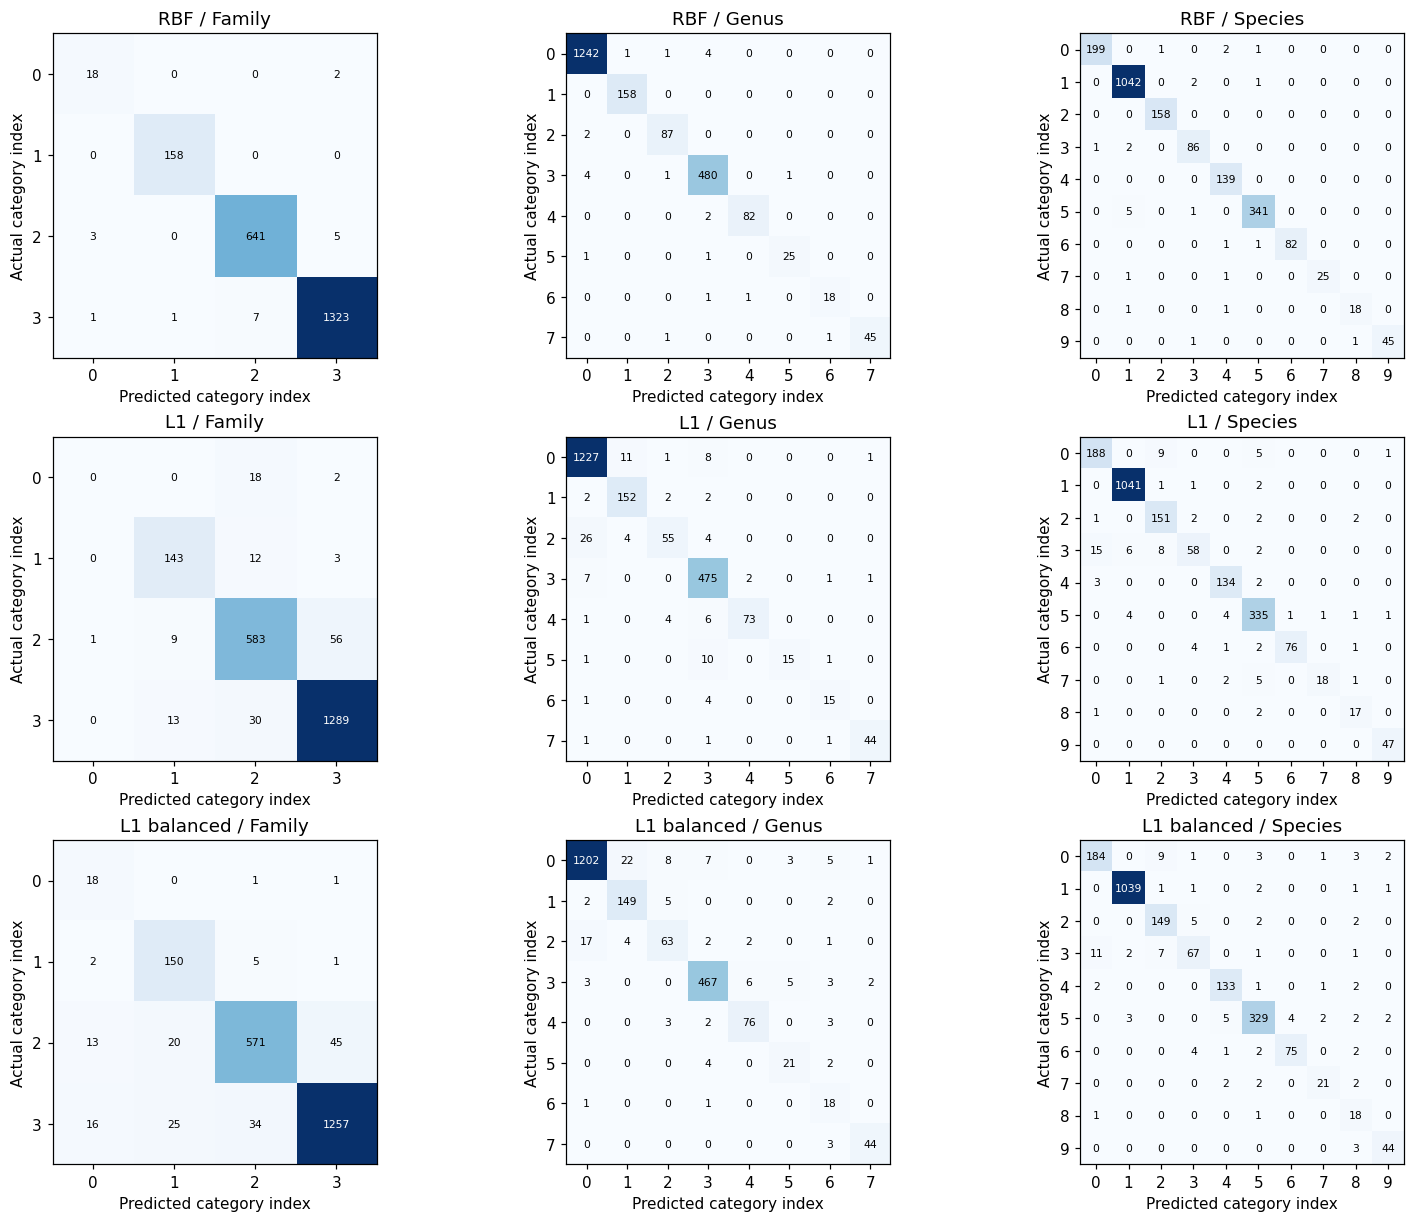

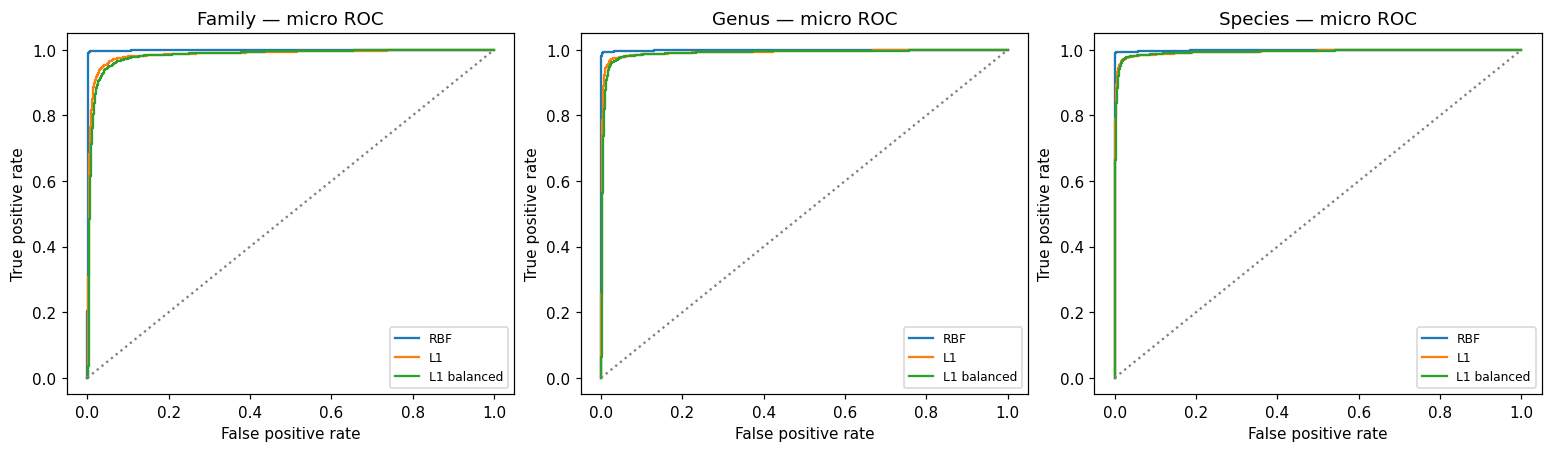

,model,split,label,accuracy,macro_precision,macro_recall,macro_F1,macro_AUC
0,RBF,Train,Family,1.000000,1.000000,1.000000,1.000000,1.000000
1,RBF,Test,Family,0.991200,0.948957,0.970229,0.959103,0.994277
2,RBF,Train,Genus,0.998610,0.996908,0.997260,0.997084,0.999953
3,RBF,Test,Genus,0.989810,0.979405,0.964992,0.972013,0.995625
4,RBF,Train,Species,0.998610,0.997261,0.997006,0.997133,0.999957
5,RBF,Test,Species,0.988884,0.983963,0.968599,0.975974,0.996385
6,L1,Train,Family,0.939237,0.693044,0.695211,0.694099,0.982400
7,L1,Test,Family,0.933302,0.682042,0.692772,0.687287,0.969535
8,L1,Train,Genus,0.957705,0.952378,0.848303,0.889895,0.989585
9,L1,Test,Genus,0.952293,0.932629,0.831414,0.870256,0.979920


The macro recall values above show how the classifiers perform when rare categories count equally, whereas Hamming loss weights every observed label equally.

In [7]:
detail=[]
fig,axes=plt.subplots(3,3,figsize=(14,11),layout="constrained")
fig2,axs=plt.subplots(1,3,figsize=(14,4),layout="constrained")
for i,(name,models) in enumerate(all_models.items()):
    for j,(label,model) in enumerate(zip(LABELS,models)):
        classes=model.classes_
        for split,x,y in [("Train",xtr,ytr),("Test",xte,yte)]:
            pred=model.predict(x); decision=model.decision_function(x)
            truth=label_binarize(y[:,j],classes=classes)
            prec,rec,f1,_=precision_recall_fscore_support(y[:,j],pred,labels=classes,average="macro",zero_division=0)
            aucs=[roc_auc_score(truth[:,k],decision[:,k]) for k in range(len(classes))]
            detail.append(dict(model=name,split=split,label=label,accuracy=accuracy_score(y[:,j],pred),
                               macro_precision=prec,macro_recall=rec,macro_F1=f1,macro_AUC=np.mean(aucs)))
            cm=confusion_matrix(y[:,j],pred,labels=classes)
            pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUT/(name.replace(" ","_")+"_"+label+"_"+split+"_confusion.csv"))
            if split=="Test":
                ax=axes[i,j];ax.imshow(cm,cmap="Blues")
                for (r,col),v in np.ndenumerate(cm): ax.text(col,r,str(v),ha="center",va="center",fontsize=7,color="white" if v>cm.max()/2 else "black")
                ax.set(title=name+" / "+label,xticks=range(len(classes)),yticks=range(len(classes)),xlabel="Predicted category index",ylabel="Actual category index")
                fpr,tpr,_=roc_curve(truth.ravel(),decision.ravel())
                axs[j].plot(fpr,tpr,label=name)
                pd.DataFrame({"fpr":fpr,"tpr":tpr}).to_csv(OUT/(name.replace(" ","_")+"_"+label+"_micro_roc.csv"),index=False)
for ax,label in zip(axs,LABELS):
    ax.plot([0,1],[0,1],":",color="gray");ax.set(title=label+" — micro ROC",xlabel="False positive rate",ylabel="True positive rate");ax.legend(fontsize=8)
plt.figure(fig.number);figure("test_confusion_matrices")
plt.figure(fig2.number);figure("test_micro_ROCs")
table(pd.DataFrame(detail),"per_output_metrics")
answer("The macro recall values above show how the classifiers perform when rare categories count equally, whereas Hamming loss weights every observed label equally.")

Weighting increases Family macro recall from 69.28% to 91.82%. In particular, the Family confusion matrices show that the unweighted linear model misses all 20 Bufonidae test cases, whereas the weighted model correctly identifies 18. The reduction in overall exact match therefore hides a gain for the rare family. The Gaussian model retains high overall accuracy while identifying 18 of those 20 cases.

Category indices in the confusion matrices:

| Index | Family | Genus | Species |
|---|---|---|---|
| 0 | Bufonidae | Adenomera | AdenomeraAndre |
| 1 | Dendrobatidae | Ameerega | AdenomeraHylaedactylus |
| 2 | Hylidae | Dendropsophus | Ameeregatrivittata |
| 3 | Leptodactylidae | Hypsiboas | HylaMinuta |
| 4 |  | Leptodactylus | HypsiboasCinerascens |
| 5 |  | Osteocephalus | HypsiboasCordobae |
| 6 |  | Rhinella | LeptodactylusFuscus |
| 7 |  | Scinax | OsteocephalusOophagus |
| 8 |  |  | Rhinellagranulosa |
| 9 |  |  | ScinaxRuber |

## 2(a). K-means and automatic selection of k
I clustered all 7,195 rows using their original normalized MFCC attributes. For each of 50 independent seeds, I fitted K-means for every k from 1 through 50, using three k-means++ initializations per candidate and retaining the smallest inertia. I selected k by the largest Calinski–Harabasz (CH) index, breaking ties in favor of smaller k. CH is undefined for one cluster, so k = 1 is recorded as a baseline but is ineligible under this criterion. True labels are not used to choose k.

The 50 repetitions vary initialization only; they reuse the same dataset. Their standard deviation describes sensitivity to initialization, not uncertainty from sampling new frogs.

,run,k,CH,exact_match,mean_hamming_distance,hamming_loss,hamming_score,jaccard_score
0,1,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
1,2,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
2,3,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
3,4,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
4,5,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
5,6,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
6,7,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
7,8,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
8,9,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189
9,10,2,3680.741349,0.636136,0.895622,0.298541,0.701459,0.68189


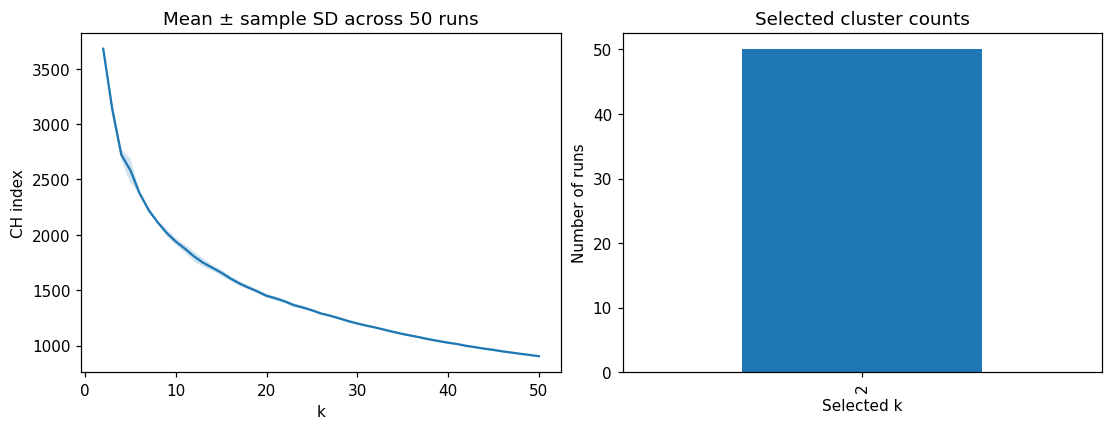

In [8]:
runs,scans,majorities=monte_carlo(X,Y,OUT)
table(runs,"kmeans_50_runs")
fig,axes=plt.subplots(1,2,figsize=(10,3.8),layout="constrained")
ch=scans.groupby("k").CH.agg(["mean","std"])
axes[0].plot(ch.index,ch["mean"]);axes[0].fill_between(ch.index,ch["mean"]-ch["std"],ch["mean"]+ch["std"],alpha=.2)
axes[0].set(xlabel="k",ylabel="CH index",title="Mean ± sample SD across 50 runs")
runs.k.value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(xlabel="Selected k",ylabel="Number of runs",title="Selected cluster counts")
figure("k_selection")

## 2(b). Majority label triplets
Within each selected cluster, I chose the most frequent Family, Genus, and Species separately. A tie goes to the alphabetically first category. The table shows the first repetition; the CSV contains every cluster from all 50 repetitions. These assignments use the true labels to evaluate the clusters retrospectively.

In [9]:
display(majorities.loc[majorities.run==1])
print("Saved majority triplets for",majorities.run.nunique(),"runs.")

Saved majority triplets for 50 runs.


,run,cluster,size,Family,Genus,Species
0,1,0,3597,Hylidae,Hypsiboas,HypsiboasCordobae
1,1,1,3598,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


## 2(c). Hamming distance, score, and loss
I assigned each row its cluster's majority-label triplet and compared all three entries with its true triplet. The reported Hamming distance is the average number of incorrect entries per row; its normalized form is Hamming loss. I used sample standard deviations (ddof = 1) over the 50 repetitions.

In [10]:
columns=["mean_hamming_distance","hamming_score","hamming_loss","exact_match","jaccard_score"]
aggregate=runs[columns].agg(["mean","std"]).T.rename_axis("metric").reset_index()
table(aggregate,"kmeans_summary")
answer(f'Mean Hamming distance = {runs.mean_hamming_distance.mean():.6f}, with sample SD {runs.mean_hamming_distance.std(ddof=1):.6f}. '
       f'Mean Hamming loss = {runs.hamming_loss.mean():.6f}; mean label-accuracy Hamming score = {runs.hamming_score.mean():.6f}.')
assert np.allclose(runs.mean_hamming_distance,3*runs.hamming_loss)

,metric,mean,std
0,mean_hamming_distance,0.895622,0.0
1,hamming_score,0.701459,0.0
2,hamming_loss,0.298541,0.0
3,exact_match,0.636136,0.0
4,jaccard_score,0.681890,0.0


Mean Hamming distance = 0.895622, with sample SD 0.000000. Mean Hamming loss = 0.298541; mean label-accuracy Hamming score = 0.701459.

All 50 repetitions select **k = 2** and yield the same evaluation metrics. The sample standard deviation is **0** to numerical precision; values near 10⁻¹⁶ in the CSV are floating-point rounding. The mean Hamming distance is **0.895622**, the Hamming loss is **0.298541**, and the label-accuracy Hamming score is **0.701459**.

The stable two-cluster solution separates broad acoustic groups, but two majority triplets cannot represent all ten species. A high CH index rewards compact, separated feature clusters; it does not guarantee agreement with the taxonomic labels. I retained the CH-selected solution rather than choosing k from label agreement.

## 3. ISLR 12.6, Exercise 2

**(a) Complete linkage.** Merge observations 1 and 2 at height 0.30. Merge 3 and 4 at 0.45. Merge the two pairs at 0.80, the largest dissimilarity across the pairs.

**(b) Single linkage.** Merge 1 and 2 at 0.30. Add observation 3 at 0.40, using the distance from 1 to 3. Add observation 4 at 0.45, using the distance from 3 to 4.

**(c)** Cutting the complete-linkage dendrogram between heights 0.45 and 0.80 gives **{1, 2}** and **{3, 4}**.

**(d)** Cutting the single-linkage dendrogram between 0.40 and 0.45 gives **{1, 2, 3}** and **{4}**.

**(e)** The third panel swaps the children within the first pair. Its leaf order changes, but every merge and merge height agrees with panel (a).

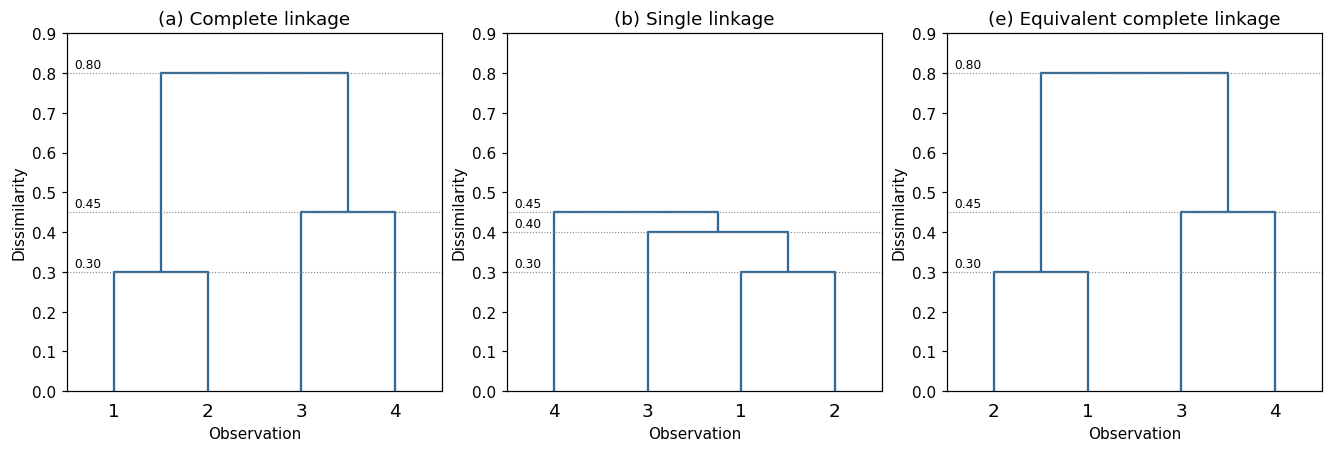

In [11]:
D=np.array([[0,.3,.4,.7],[.3,0,.5,.8],[.4,.5,0,.45],[.7,.8,.45,0]])
complete=linkage(squareform(D),method="complete")
single=linkage(squareform(D),method="single")
equivalent=complete.copy();equivalent[0,:2]=equivalent[0,:2][::-1]
fig,axes=plt.subplots(1,3,figsize=(12,4),layout="constrained")
for ax,Z,title in zip(axes,[complete,single,equivalent],["(a) Complete linkage","(b) Single linkage","(e) Equivalent complete linkage"]):
    dendrogram(Z,labels=["1","2","3","4"],ax=ax,color_threshold=0,above_threshold_color="#306998")
    for height in Z[:,2]:
        ax.axhline(height,ls=":",lw=.7,color="gray");ax.text(.8,height+.012,f"{height:.2f}",fontsize=8)
    ax.set(title=title,xlabel="Observation",ylabel="Dissimilarity",ylim=(0,.9))
figure("islr_dendrograms")
assert np.allclose(complete[:,2],[.3,.45,.8]) and np.allclose(single[:,2],[.3,.4,.45])

## References
- Colonna et al., [Anuran Calls (MFCCs), UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/406/anuran+calls+mfccs). The supplied Readme documents normalization and recording IDs.
- [scikit-learn: OneVsRestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.multiclass.OneVsRestClassifier.html).
- [scikit-learn: LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html).
- [scikit-learn: Hamming loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.hamming_loss.html).
- [scikit-learn: Jaccard score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.jaccard_score.html).
- [scikit-learn: Calinski–Harabasz index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.calinski_harabasz_score.html).
- James, Witten, Hastie and Tibshirani, [An Introduction to Statistical Learning, second edition](https://www.statlearning.com/), Section 12.6, Exercise 2.